# Step 1. Prepare the data and the image processing

The goal of the project is to sort tomato leaf photos into three classes. The classes are **healthy**, **early blight** and **late blight**. We also test whether two clean-up methods help when photos are dark or noisy. The two methods are **CLAHE** and a **median filter**.

This notebook does all of Step 1 in four parts.

| Part | What we do | What we get |
|---|---|---|
| **1a** | Pick the photos and split them into train, validation and test | `outputs/manifest.csv` |
| **1b** | Look at the dataset | Count table, example photos, size check, brightness histograms |
| **1c** | Build CLAHE and the median filter and choose their settings | Before and after figures and the chosen settings |
| **1d** | Make dark and noisy copies of the test photos | `outputs/corrupted_test/` |

Follow these rules in every step.
- The **train** photos are what the models learn from.
- The **validation** photos are where we choose settings.
- The **test** photos are the final exam. We use them only at the very end.
- All photos of the same leaf stay in the same group.
- Every random step uses a fixed **seed**. This means everyone gets the same result.

Every figure is saved in `outputs/figures/`. You can put them straight into your slides.

---
## 1a. Get the data

### Set up the tools and folders

This cell does four things.
1. It loads the tools we need. We use `pandas` for tables, `numpy` for maths on pixels, `cv2` and `PIL` for images, and `matplotlib` for charts.
2. It sets the seed. The seed makes every shuffle come out the same way each time.
3. It sets the folder paths. Python then knows where the photos are and where to save results.
4. It lists the 3 classes we keep and gives each one a short name.

Both lines at the end should print `True`.

In [1]:
import os, json, random
from pathlib import Path

import numpy as np                 # maths on pixel arrays
import pandas as pd                # tables, like a spreadsheet in Python
import cv2                         # OpenCV for CLAHE, median filter and colours
from PIL import Image              # opening image files
import matplotlib.pyplot as plt    # drawing charts and image grids

# Make randomness repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Where things are
ROOT = Path.home() / "DImProj"                                  # project folder
RAW = ROOT / "PlantVillage-Dataset" / "raw" / "color"           # original colour photos
LEAF_MAP_PATH = ROOT / "PlantVillage-Dataset" / "leaf-map.json" # which photo shows which leaf
OUT = ROOT / "outputs"                                          # everything we produce
FIG = OUT / "figures"                                           # figures for slides
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

# The 3 classes we keep (folder name to short label)
CLASSES = {
    "Tomato___healthy":      "healthy",
    "Tomato___Early_blight": "early_blight",
    "Tomato___Late_blight":  "late_blight",
}
LABELS = list(CLASSES.values())

# Both should print True
print("Photo folder found:", RAW.exists())
print("Leaf map found:   ", LEAF_MAP_PATH.exists())

Photo folder found: True
Leaf map found:    True


### Make a table of every photo and its leaf

Most leaves were photographed about 4 times. All photos of one leaf must stay in the same group. If they get split up, the model can learn to recognise the leaf itself. Its test score would then look better than it really is.

The file `leaf-map.json` tells us which leaf each photo shows. It works like a phone book.

Here is how we look up one photo.
1. Start with the file name, for example `0034a551-...___RS_Erly.B 9432.JPG`.
2. Remove the random code at the start and `.JPG` at the end. Then make it lower case. This gives `rs_erly.b 9432`.
3. Look up that name. The answer is `Tomato___Early_blight:::123.0`. This means early blight, leaf number 123.

Some names are listed under more than one plant. We keep only the answer that matches the photo's own folder.

A photo is **mapped** when we find it in the phone book. A photo is **unmapped** when we cannot find it. We still know the class of an unmapped photo from its folder. We just do not know which leaf it shows.

In [2]:
leaf_map = json.load(open(LEAF_MAP_PATH))   # photo name to leaf lookup

rows = []
for folder, label in CLASSES.items():
    for fname in sorted(os.listdir(RAW / folder)):
        # Turn the file name into the lookup name
        key = fname.split("___", 1)[1].rsplit(".", 1)[0].lower()

        # Keep only the answer for this folder's class
        leaf_id = None
        for entry in leaf_map.get(key, []):
            cls, lid = entry.split(":::")
            if cls == folder:
                # Add the label so leaf IDs stay unique across classes
                leaf_id = f"{label}_{int(float(lid))}"

        rows.append({"path": str(RAW / folder / fname), "label": label,
                     "key": key, "leaf_id": leaf_id})

df_all = pd.DataFrame(rows)
df_all["mapped"] = df_all["leaf_id"].notna()   # True if we found the leaf

# Count mapped and unmapped photos per class
print(df_all.groupby(["label", "mapped"]).size())

label         mapped
early_blight  False       1
              True      999
healthy       False     592
              True      999
late_blight   False     989
              True      920
dtype: int64


### Keep only the mapped photos

We remove the unmapped photos for two reasons.
1. We cannot keep their leaf's photos together, so they could leak between groups.
2. They come from a different photo collection called `GH`. Early blight has almost no `GH` photos. If we mixed them in, the model could learn the photo setup instead of the disease.

This leaves about 1,000 photos per class. That is the size the plan asked for.

The last printout is a check. Almost every leaf should have exactly 4 photos.

In [3]:
df = df_all[df_all["mapped"]].copy().reset_index(drop=True)

summary = df.groupby("label").agg(photos=("path", "count"),
                                  leaves=("leaf_id", "nunique"))   # nunique = number of different leaves
summary["photos_per_leaf"] = (summary["photos"] / summary["leaves"]).round(2)
print(summary)
print("\nTotal photos kept:", len(df))
print("Total leaves:     ", df["leaf_id"].nunique())

print("\nPhotos per leaf to number of leaves:")
print(df.groupby("leaf_id").size().value_counts().sort_index())

              photos  leaves  photos_per_leaf
label                                        
early_blight     999     250              4.0
healthy          999     250              4.0
late_blight      920     230              4.0

Total photos kept: 2918
Total leaves:      730

Photos per leaf to number of leaves:
3      2
4    728
Name: count, dtype: int64


### Split the leaves into train, validation and test

We use a 70, 15, 15 split. Think of each leaf as a playing card. We do the following for each class on its own.
1. List the leaves of that class and shuffle them with our seed.
2. Give the first 70% to **train**, the next 15% to **validation** and the rest to **test**.
3. Give every photo the same group as its leaf. All photos of a leaf now move together.

Doing each class on its own keeps the same class mix in all three groups.

The check at the end must print three zeros. A zero means no leaf is shared between two groups.

In [4]:
rng = np.random.default_rng(SEED)
leaf_split = {}                                  # leaf to group

for label in LABELS:
    leaves = sorted(df.loc[df["label"] == label, "leaf_id"].unique())  # fixed starting order
    rng.shuffle(leaves)                                                # shuffle the leaves
    n_train = round(len(leaves) * 0.70)
    n_val   = round(len(leaves) * 0.15)
    for i, leaf in enumerate(leaves):
        if i < n_train:
            leaf_split[leaf] = "train"
        elif i < n_train + n_val:
            leaf_split[leaf] = "val"
        else:
            leaf_split[leaf] = "test"

df["split"] = df["leaf_id"].map(leaf_split)      # each photo gets its leaf's group

# Photos per class (rows) and group (columns)
print(pd.crosstab(df["label"], df["split"], margins=True))

# Check that no leaf is in two groups
groups = {s: set(df.loc[df["split"] == s, "leaf_id"]) for s in ["train", "val", "test"]}
print("\nLeaves shared train & val: ", len(groups["train"] & groups["val"]))
print("Leaves shared train & test:", len(groups["train"] & groups["test"]))
print("Leaves shared val & test:  ", len(groups["val"] & groups["test"]))

split         test  train  val   All
label                               
early_blight   148    699  152   999
healthy        148    699  152   999
late_blight    140    644  136   920
All            436   2042  440  2918

Leaves shared train & val:  0
Leaves shared train & test: 0
Leaves shared val & test:   0


### Save the split and never change it

The saved split is called the **manifest**. It lists which group each photo belongs to. Every later notebook loads this file. This way all 5 experiment runs use exactly the same photos.

- The paths start at `PlantVillage-Dataset/...`. This lets them work on a teammate's computer too.
- If a manifest already exists, this cell leaves it alone. It only checks that today's split is the same. This protects the split from accidental changes.

In [5]:
manifest_new = df[["path", "label", "leaf_id", "split"]].copy()
manifest_new["path"] = manifest_new["path"].str.replace(str(ROOT) + "/", "", regex=False)

MANIFEST = OUT / "manifest.csv"
if MANIFEST.exists():
    saved = pd.read_csv(MANIFEST)
    same = saved.sort_values("path").reset_index(drop=True).equals(
           manifest_new.sort_values("path").reset_index(drop=True))
    print("Manifest already exists, NOT overwriting. Matches today's split:", same)
else:
    manifest_new.to_csv(MANIFEST, index=False)
    print("Saved new manifest to", MANIFEST)

Manifest already exists, NOT overwriting. Matches today's split: True


### Load the manifest

From here on we only use the manifest file. The Step 2 notebooks will do the same.

We add a column called `full_path`. It puts the project folder in front of each short path so Python can find the photo on this computer.

The photos are already 256 by 256 pixels. We keep that size for the image processing and the SVM. In Step 2 the CNN will cut a 224 by 224 square from the centre of each photo. ResNet-18 was trained on photos of that size.

In [6]:
manifest = pd.read_csv(OUT / "manifest.csv")
manifest["full_path"] = manifest["path"].apply(lambda p: str(ROOT / p))

def load_rgb(path):
    # Open a photo as an array of pixels
    return np.array(Image.open(path).convert("RGB"))

print(manifest.shape)
manifest.head()

(2918, 5)


,path,label,leaf_id,split,full_path
0,PlantVillage-Dataset/raw/color/Tomato___health...,healthy,healthy_26,train,/home/justa/DImProj/PlantVillage-Dataset/raw/c...
1,PlantVillage-Dataset/raw/color/Tomato___health...,healthy,healthy_214,train,/home/justa/DImProj/PlantVillage-Dataset/raw/c...
2,PlantVillage-Dataset/raw/color/Tomato___health...,healthy,healthy_56,test,/home/justa/DImProj/PlantVillage-Dataset/raw/c...
3,PlantVillage-Dataset/raw/color/Tomato___health...,healthy,healthy_163,train,/home/justa/DImProj/PlantVillage-Dataset/raw/c...
4,PlantVillage-Dataset/raw/color/Tomato___health...,healthy,healthy_27,train,/home/justa/DImProj/PlantVillage-Dataset/raw/c...


---
## 1b. Show the dataset

### Count the photos in each group

This table goes in your slides. It shows that each group has a similar mix of the 3 classes.

It is saved as `outputs/figures/split_counts.csv`.

In [7]:
counts = pd.crosstab(manifest["label"], manifest["split"], margins=True, margins_name="total")
counts = counts[["train", "val", "test", "total"]]          # put columns in a sensible order
counts.to_csv(FIG / "split_counts.csv")
counts

split,train,val,test,total
label,,,,
early_blight,699,152,148,999
healthy,699,152,148,999
late_blight,644,136,140,920
total,2042,440,436,2918


### Check the size and colour type of every photo

We open every photo and record two things.
- The **size** in pixels. Every photo should be (256, 256).
- The **mode**, which is the colour type. Every photo should be `RGB`, meaning normal colour.

If any photo is different, we want to find out now.

In [8]:
sizes, modes = [], []
for p in manifest["full_path"]:
    with Image.open(p) as im:        # open the photo and close it after
        sizes.append(im.size)
        modes.append(im.mode)
manifest["size"] = sizes
manifest["mode"] = modes

print(manifest["size"].value_counts())
print(manifest["mode"].value_counts())

size
(256, 256)    2918
Name: count, dtype: int64
mode
RGB    2918
Name: count, dtype: int64


### Show example photos from each class

This makes a grid with 3 rows and 4 columns. Each row is one class. Each photo is a random training photo.

We only use training photos for figures. This keeps the test photos unseen.

Here is what to look for.
- **Healthy** leaves are evenly green.
- **Early blight** leaves have brown spots, often with rings like a target.
- **Late blight** leaves have larger, darker patches with uneven edges.

Ask yourself whether you can always tell early and late blight apart. The models face the same problem.

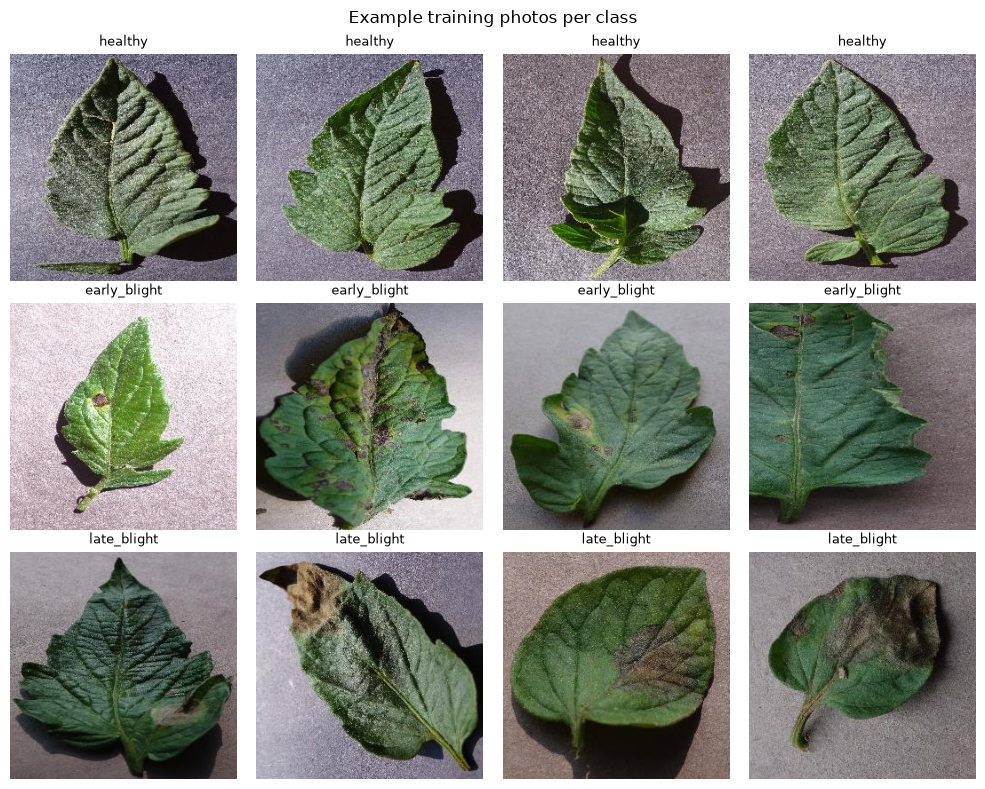

In [9]:
train = manifest[manifest["split"] == "train"]

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for row, label in enumerate(LABELS):
    picks = train[train["label"] == label].sample(4, random_state=SEED)   # same 4 every time
    for col, p in enumerate(picks["full_path"]):
        ax = axes[row, col]
        ax.imshow(load_rgb(p))
        ax.set_title(label, fontsize=9)
        ax.axis("off")                       # hide tick marks
plt.suptitle("Example training photos per class")
plt.tight_layout()
plt.savefig(FIG / "examples_per_class.png", dpi=150)
plt.show()

### Brightness histograms (L02 and L03)

A **histogram** counts how many pixels have each brightness level. Level 0 is black and level 255 is white.

We measure brightness with the **L channel** of the CIELAB colour space. L stands for lightness. It holds how bright a pixel is and leaves the colour out. CLAHE will use this same channel later.

The cell draws two charts.
1. The left chart shows the average brightness histogram of each class over all training photos. Use it to see if one class is brighter than the others.
2. The right chart shows the mean brightness of each photo. Use it to see how much the lighting changes from photo to photo.

This matters because a model could take a shortcut. If one class were always darker, the model could learn that darkness means that class. The dark test in 1d checks how much the models rely on brightness.

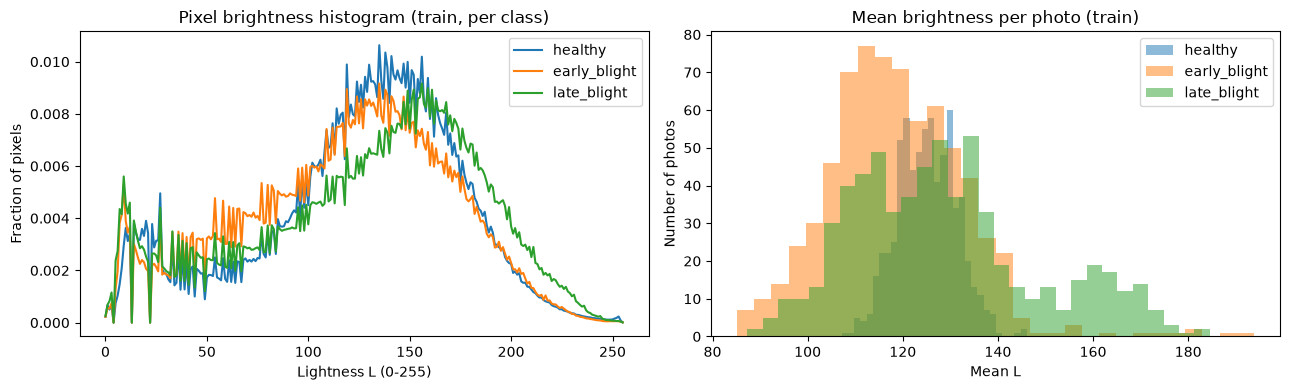

              count   mean   std    min    25%    50%    75%    max
label                                                              
early_blight  699.0  118.6  14.3   85.1  109.5  117.7  127.5  193.9
healthy       699.0  125.1   6.1  107.2  120.5  125.2  129.5  146.1
late_blight   644.0  128.7  19.6   87.3  113.8  126.6  138.5  184.5


In [10]:
def lightness(rgb):
    # Get the lightness channel of a photo
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[:, :, 0]

hist_sum = {lab: np.zeros(256) for lab in LABELS}   # running total of pixel counts per class
mean_L = []                                          # one mean brightness per photo

for _, r in train.iterrows():
    L = lightness(load_rgb(r["full_path"]))
    hist_sum[r["label"]] += np.bincount(L.ravel(), minlength=256)   # count pixels at each level
    mean_L.append(L.mean())
train = train.assign(mean_L=mean_L)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lab in LABELS:
    h = hist_sum[lab] / hist_sum[lab].sum()          # turn counts into fractions
    axes[0].plot(h, label=lab)
    axes[1].hist(train.loc[train["label"] == lab, "mean_L"], bins=30, alpha=0.5, label=lab)
axes[0].set(title="Pixel brightness histogram (train, per class)", xlabel="Lightness L (0-255)", ylabel="Fraction of pixels")
axes[1].set(title="Mean brightness per photo (train)", xlabel="Mean L", ylabel="Number of photos")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG / "brightness_histograms.png", dpi=150)
plt.show()

print(train.groupby("label")["mean_L"].describe().round(1))

### Notes for the slides

- **Early and late blight can look alike.** Both cause brown, dead patches. Expect most mistakes between these two classes.
- **Lab photos are different from farm photos.** Each photo shows one leaf on a plain background in steady light. Farm photos have clutter, shadows and many leaves. Our results will probably be better than results in a real field.
- **The photo setup can match the class.** PlantVillage photographed each class in batches. The background and lighting can therefore give hints about the label. Using only the `RS_` photos reduces this problem. It does not remove it. Mention this under Limitations.

---
## 1c. Build the two processing methods

| Method | What it does | Lecture |
|---|---|---|
| **A. CLAHE** | Raises the local contrast so dark or flat areas become visible | L02 colour models, L03 histogram equalization and CLAHE |
| **B. Median filter** | Removes salt and pepper noise, which is random white and black dots | L03 order statistic filters |

**How CLAHE works**
- Normal histogram equalization stretches the brightness of the whole image at once.
- CLAHE splits the image into small tiles, such as an 8 by 8 grid. Each tile gets its own contrast boost.
- The **clip limit** stops any brightness level from being boosted too much. This keeps noise from getting worse.
- We apply CLAHE to the L channel only. Changing the red, green and blue channels on their own would shift the colours. Colour is what tells the diseases apart, so we keep it the same.

**How the median filter works**
- Each pixel is replaced by the middle value of the pixels around it. A 3 by 3 window uses 9 pixels.
- A noise dot is very bright or very dark. It is never the middle value, so it gets removed.
- Edges stay sharper than with a simple average.
- In method A+B we run CLAHE first and the median filter second.

In [11]:
def apply_clahe(rgb, clip=2.0, grid=8):
    # Method A, CLAHE on the lightness channel
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)                         # RGB to CIELAB
    L, a, b = cv2.split(lab)                                          # separate lightness from colour
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid))
    L = clahe.apply(L)                                                # equalize lightness only
    return cv2.cvtColor(cv2.merge([L, a, b]), cv2.COLOR_LAB2RGB)      # back to RGB

def apply_median(rgb, k=3):
    # Method B, median filter with a k by k window
    return cv2.medianBlur(rgb, k)

def apply_AB(rgb, clip=2.0, grid=8, k=3):
    # Method A then method B
    return apply_median(apply_clahe(rgb, clip, grid), k)

print("Processing functions ready.")

Processing functions ready.


### Make the corruption functions

To choose good settings, we need to see how the methods handle dark and noisy photos. So we write the two corruptions now. We use them again in 1d.

**Darkening with gamma (L02)**
1. Scale every pixel to a value between 0 and 1.
2. Raise it to the power γ. The formula is I′ = I^γ.
3. When γ is above 1 the image gets darker. For example 0.5 becomes 0.35 when γ is 1.5.
4. A γ of 2.0 is darker than a γ of 1.5.

**Salt and pepper noise**
1. Pick a small share of pixels at random, such as 1%.
2. Make half of them white. This is the salt.
3. Make the other half black. This is the pepper.

For tuning we corrupt the **validation** photos. The **test** copies are made once in 1d. We never tune on them.

In [12]:
def darken(rgb, gamma):
    # Darken a photo with gamma
    I = rgb.astype(np.float32) / 255.0
    return np.clip((I ** gamma) * 255.0 + 0.5, 0, 255).astype(np.uint8)   # round to whole numbers

def salt_pepper(rgb, amount, seed):
    # Add salt and pepper noise
    rng = np.random.default_rng(seed)
    out = rgb.copy()
    h, w = rgb.shape[:2]
    n = int(round(amount * h * w))                       # how many pixels to hit
    idx = rng.choice(h * w, size=n, replace=False)       # pick which pixels
    ys, xs = np.unravel_index(idx, (h, w))
    half = n // 2
    out[ys[:half], xs[:half]] = 255                      # salt (white)
    out[ys[half:], xs[half:]] = 0                        # pepper (black)
    return out

print("Corruption functions ready.")

Corruption functions ready.


### Show what each method does

We take one validation photo and show it in a grid.
- Each row is one condition. The rows are the clean photo, the photo darkened with γ 2.0, and the photo with 3% noise.
- The columns show the input, the result of A, the result of B and the result of A+B.
- The last column compares the brightness histogram of the input with the result of A+B.

We use the starting settings from the plan. These are a clip limit of 2.0, an 8 by 8 grid and a 3 by 3 median window.

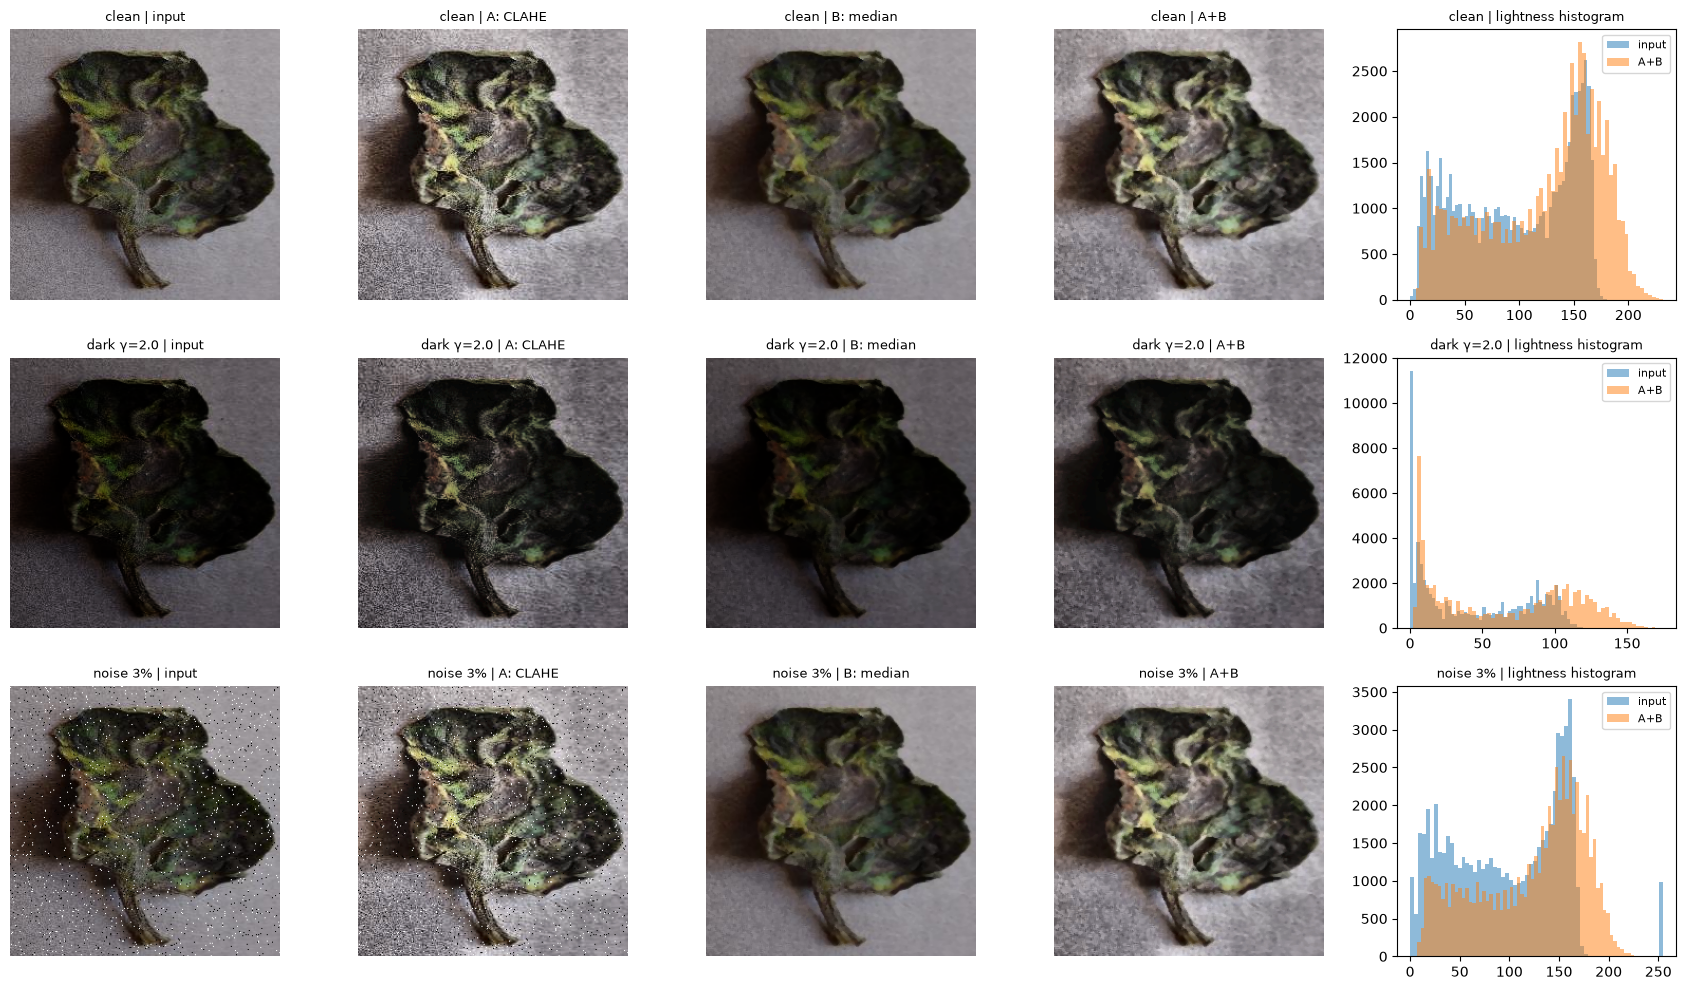

In [13]:
val = manifest[manifest["split"] == "val"]
demo_path = val[val["label"] == "early_blight"].sample(1, random_state=SEED)["full_path"].iloc[0]
clean = load_rgb(demo_path)

conditions = {"clean": clean,
              "dark γ=2.0": darken(clean, 2.0),
              "noise 3%": salt_pepper(clean, 0.03, seed=SEED)}

fig, axes = plt.subplots(3, 5, figsize=(17, 10))
for row, (name, img) in enumerate(conditions.items()):
    versions = {"input": img, "A: CLAHE": apply_clahe(img),
                "B: median": apply_median(img), "A+B": apply_AB(img)}
    for col, (vname, v) in enumerate(versions.items()):
        axes[row, col].imshow(v)
        axes[row, col].set_title(f"{name} | {vname}", fontsize=9)
        axes[row, col].axis("off")
    # Last column shows the brightness histogram
    axes[row, 4].hist(lightness(img).ravel(), bins=64, alpha=0.5, label="input")
    axes[row, 4].hist(lightness(versions["A+B"]).ravel(), bins=64, alpha=0.5, label="A+B")
    axes[row, 4].set_title(f"{name} | lightness histogram", fontsize=9)
    axes[row, 4].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "before_after_methods.png", dpi=150)
plt.show()

### Tune the settings on validation photos

The plan says to choose the settings using validation photos only. We do a simple test here. In Step 2 we confirm the choice with the models' validation scores.

We measure each result with **PSNR**. It compares a processed photo with the clean photo. A higher PSNR means the two are more alike. It is measured in dB.

**Median window size**
1. Add 1% or 3% noise to validation photos.
2. Run the median filter with a 3 by 3, 5 by 5 or 7 by 7 window.
3. Compare the result with the clean photo.

A bigger window removes more noise. It also blurs more real detail, such as small disease spots. PSNR shows this trade-off.

**CLAHE clip limit and grid size**
1. Darken validation photos with γ 2.0.
2. Run CLAHE with each clip limit and grid size.
3. Compare the result with the clean photo.

Also look at the pictures in the next cells. A high clip limit can make the leaf look grainy.

CLAHE is a contrast method. It does not try to restore the original brightness. So treat PSNR here as a rough guide.

We use 60 validation photos, 20 per class, to keep it quick.

In [14]:
def psnr(a, b):
    # Measure how alike two photos are
    mse = np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

tune = val.groupby("label").sample(20, random_state=SEED)       # 20 val photos per class
tune_imgs = [load_rgb(p) for p in tune["full_path"]]

# Median window size
med_rows = []
for amount in [0.01, 0.03]:
    for k in [3, 5, 7]:
        scores = [psnr(apply_median(salt_pepper(im, amount, seed=SEED + i), k), im)
                  for i, im in enumerate(tune_imgs)]
        med_rows.append({"noise": f"{int(amount*100)}%", "window": f"{k}x{k}", "PSNR_dB": np.mean(scores)})
# Noisy photo with no filter, for comparison
for amount in [0.01, 0.03]:
    scores = [psnr(salt_pepper(im, amount, seed=SEED + i), im) for i, im in enumerate(tune_imgs)]
    med_rows.append({"noise": f"{int(amount*100)}%", "window": "none", "PSNR_dB": np.mean(scores)})
med_table = pd.DataFrame(med_rows).pivot(index="window", columns="noise", values="PSNR_dB").round(2)
print("Median filter: PSNR vs clean photo (higher is better)")
print(med_table, "\n")

# CLAHE clip limit and grid size
clahe_rows = []
for clip in [1.0, 2.0, 3.0, 4.0]:
    for grid in [4, 8, 16]:
        scores = [psnr(apply_clahe(darken(im, 2.0), clip, grid), im) for im in tune_imgs]
        clahe_rows.append({"clip": clip, "grid": grid, "PSNR_dB": np.mean(scores)})
no_clahe = np.mean([psnr(darken(im, 2.0), im) for im in tune_imgs])
clahe_table = pd.DataFrame(clahe_rows).pivot(index="clip", columns="grid", values="PSNR_dB").round(2)
print("CLAHE on dark (γ=2.0) photos: PSNR vs clean photo (higher is better)")
print(clahe_table)
print(f"Reference, dark photo with no CLAHE: {no_clahe:.2f} dB")

med_table.to_csv(FIG / "tuning_median_psnr.csv")
clahe_table.to_csv(FIG / "tuning_clahe_psnr.csv")

Median filter: PSNR vs clean photo (higher is better)
noise          1%         3%
window                      
3x3     24.059999  23.990000
5x5     23.240000  23.209999
7x7     22.660000  22.639999
none    25.280001  20.490000 



CLAHE on dark (γ=2.0) photos: PSNR vs clean photo (higher is better)
grid         4          8          16
clip                                 
1.0   16.850000  16.540001  18.450001
2.0   18.370001  17.740000  18.990000
3.0   18.240000  17.709999  18.790001
4.0   17.740000  17.280001  18.190001
Reference, dark photo with no CLAHE: 13.57 dB


### What the tuning results show

**Median filter**
- The 3 by 3 window is the best. The 5 by 5 and 7 by 7 windows blur more detail and always score lower.
- At 3% noise the filter helps a lot. PSNR goes from about 20.5 to 24.0 dB.
- At 1% noise the filter scores a little lower than doing nothing. PSNR goes from about 25.3 to 24.1 dB. There are so few dots that the small blur costs more than it gains. This is a fair result to report. The median filter is only worth using when there is enough noise.

**CLAHE**
- Every setting improves the dark photos. PSNR goes from about 13.6 to between 17 and 19 dB.
- A clip limit of 2.0 is the best in every column.
- A 16 by 16 grid scores a little higher than 8 by 8. The gap is small.
- We keep the plan's default of 2.0 and 8 by 8. Change it if the pictures or the Step 2 scores favour another setting. To use 16, change `clahe_grid` in the settings cell below.

### Compare the CLAHE settings by eye

This shows the same dark validation photo with each clip limit. The grid stays at 8 by 8.

A low clip limit gives a gentle change. A high clip limit gives a strong change and can look grainy. Pick a setting that brings back leaf detail and still looks natural.

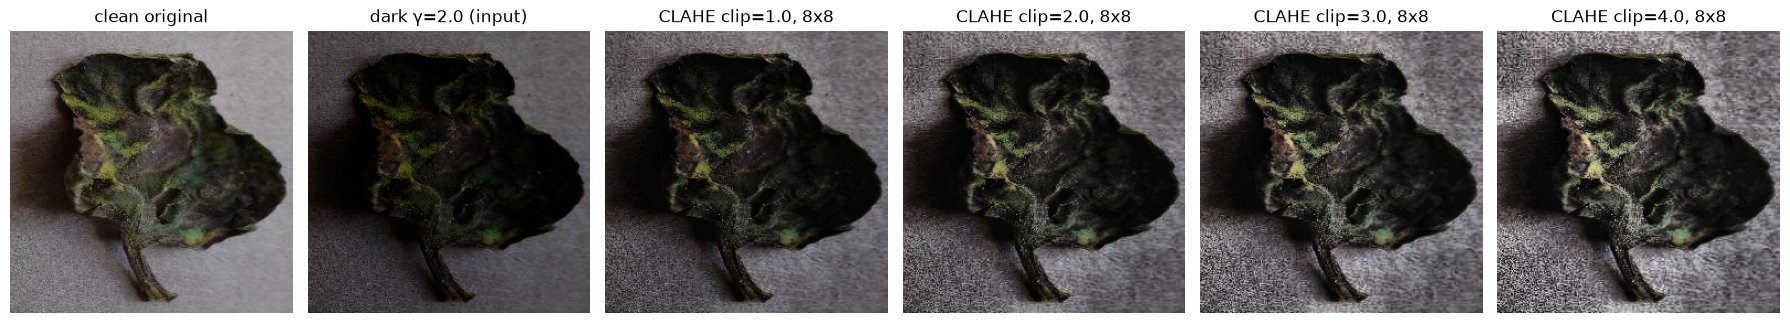

In [15]:
dark = darken(clean, 2.0)
clips = [1.0, 2.0, 3.0, 4.0]
fig, axes = plt.subplots(1, len(clips) + 2, figsize=(18, 3.6))
axes[0].imshow(clean); axes[0].set_title("clean original")
axes[1].imshow(dark);  axes[1].set_title("dark γ=2.0 (input)")
for ax, c in zip(axes[2:], clips):
    ax.imshow(apply_clahe(dark, clip=c, grid=8)); ax.set_title(f"CLAHE clip={c}, 8x8")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "clahe_clip_comparison.png", dpi=150)
plt.show()

### Choose and save the settings

Look at the tables and pictures above. Then edit the three numbers in this cell and run it. The settings are saved to `outputs/processing_settings.json`. Step 2 loads them from there.

Use these steps to decide.
1. For the median window, pick the size with the best PSNR. If two sizes are close, pick the smaller one. It erases less real detail.
2. For CLAHE, pick a setting with a good PSNR that also looks natural. If the numbers are close, keep the plan's default of 2.0 and 8 by 8.

The numbers below are the plan's starting values.

In [16]:
SETTINGS = {
    "clahe_clip": 2.0,     # edit this
    "clahe_grid": 8,       # edit this
    "median_k":   3,       # edit this, use an odd number
    "seed": SEED,
    "note": "Chosen on validation photos only (Step 1c).",
}
json.dump(SETTINGS, open(OUT / "processing_settings.json", "w"), indent=2)
print(json.dumps(SETTINGS, indent=2))

{
  "clahe_clip": 2.0,
  "clahe_grid": 8,
  "median_k": 3,
  "seed": 42,
  "note": "Chosen on validation photos only (Step 1c)."
}


### Run the two checks from the plan

**Check 1.** Does CLAHE make the noise dots worse? We apply CLAHE to a noisy photo. If the dots become easier to see, that is a good reason to add the median filter after it.

**Check 2.** Does the median filter erase real disease spots? We zoom into a clean diseased photo before and after filtering. If small spots disappear, the window is too big.

We zoom into the centre of the leaf, from pixel 80 to pixel 176. Disease spots are usually there.

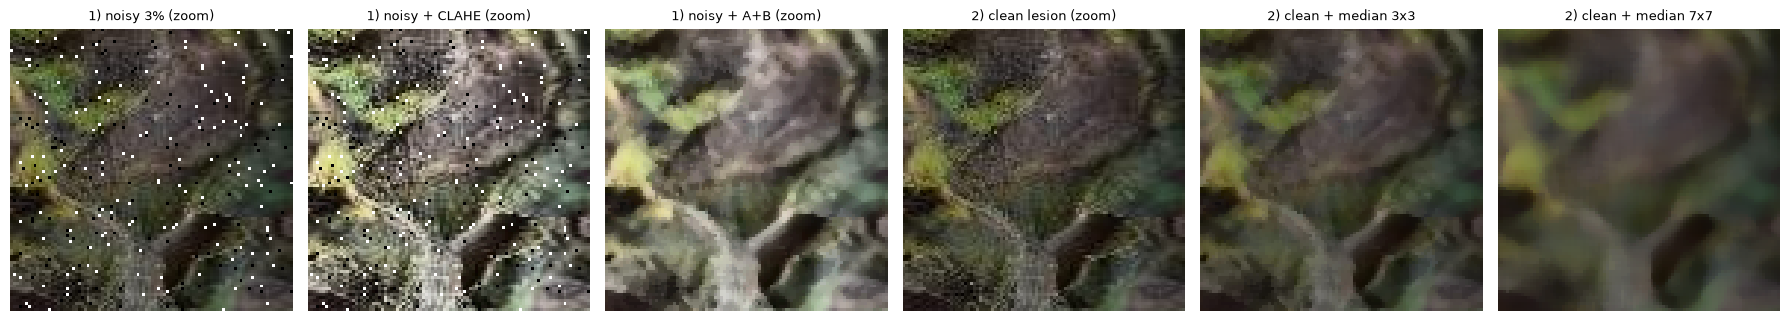

In [17]:
c, g, k = SETTINGS["clahe_clip"], SETTINGS["clahe_grid"], SETTINGS["median_k"]
zoom = (slice(80, 176), slice(80, 176))            # centre 96x96 crop

noisy = salt_pepper(clean, 0.03, seed=SEED)
panels = {
    "1) noisy 3% (zoom)":        noisy[zoom],
    "1) noisy + CLAHE (zoom)":   apply_clahe(noisy, c, g)[zoom],
    "1) noisy + A+B (zoom)":     apply_AB(noisy, c, g, k)[zoom],
    "2) clean lesion (zoom)":    clean[zoom],
    f"2) clean + median {k}x{k}": apply_median(clean, k)[zoom],
    "2) clean + median 7x7":     apply_median(clean, 7)[zoom],
}
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, (title, img) in zip(axes, panels.items()):
    ax.imshow(img, interpolation="nearest")       # show real pixels without smoothing
    ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "checks_specks_and_spots.png", dpi=150)
plt.show()

---
## 1d. Build the corruption tests

We make 4 corrupted copies of every **test** photo.

| Condition | How it is made |
|---|---|
| `dark_g1.5` | Gamma darkening with γ 1.5 |
| `dark_g2.0` | Gamma darkening with γ 2.0 |
| `noise_1` | 1% salt and pepper noise |
| `noise_3` | 3% salt and pepper noise |

The original test photos plus these 4 copies make the **5 test conditions**. Every model is scored on all 5 in Step 3.

Follow these rules.
1. Make the copies once and save them. Every model then sees exactly the same pixels.
2. Use fixed seeds. Each photo gets its own seed, which is the base seed plus the photo number.
3. Save as PNG. JPEG would smear the noise dots and change the test.
4. Never train or tune on these copies.

The cell also writes `outputs/corrupted_test/corrupted_manifest.csv`. It lists every copy with its original photo, label and condition.

It takes about a minute to run.

In [18]:
CORR = OUT / "corrupted_test"
CONDITIONS = {
    "dark_g1.5": lambda img, s: darken(img, 1.5),
    "dark_g2.0": lambda img, s: darken(img, 2.0),
    "noise_1":   lambda img, s: salt_pepper(img, 0.01, seed=s),
    "noise_3":   lambda img, s: salt_pepper(img, 0.03, seed=s),
}

test = manifest[manifest["split"] == "test"].reset_index(drop=True)
records = []
for i, r in test.iterrows():
    img = load_rgb(r["full_path"])
    stem = Path(r["path"]).stem                     # filename without folder or extension
    for cond, fn in CONDITIONS.items():
        out_dir = CORR / cond / r["label"]
        out_dir.mkdir(parents=True, exist_ok=True)
        out_path = out_dir / f"{stem}.png"
        if not out_path.exists():                   # make each copy only once
            Image.fromarray(fn(img, SEED + i)).save(out_path)
        records.append({"path": str(out_path.relative_to(ROOT)), "orig_path": r["path"],
                        "label": r["label"], "leaf_id": r["leaf_id"], "condition": cond})

corr_manifest = pd.DataFrame(records)
corr_manifest.to_csv(CORR / "corrupted_manifest.csv", index=False)
print(pd.crosstab(corr_manifest["label"], corr_manifest["condition"]))

condition     dark_g1.5  dark_g2.0  noise_1  noise_3
label                                               
early_blight        148        148      148      148
healthy             148        148      148      148
late_blight         140        140      140      140


### Check the corrupted copies

This shows one test photo in all 5 conditions.

It also measures how many pixels are pure white or pure black in the noisy copies. The answers should be about 1% and 3%.

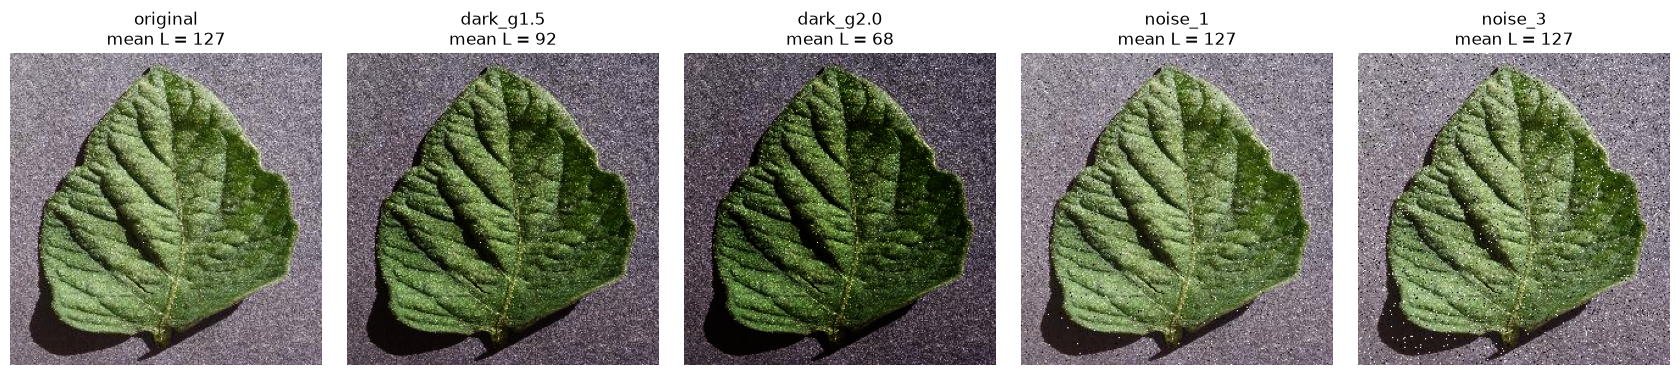

noise_1: 1.00% of pixels are pure white/black
noise_3: 3.00% of pixels are pure white/black


In [19]:
r = test.iloc[0]
stem = Path(r["path"]).stem
imgs = {"original": load_rgb(r["full_path"])}
for cond in CONDITIONS:
    imgs[cond] = load_rgb(CORR / cond / r["label"] / f"{stem}.png")

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (name, im) in zip(axes, imgs.items()):
    ax.imshow(im); ax.set_title(f"{name}\nmean L = {lightness(im).mean():.0f}"); ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "corruption_examples.png", dpi=150)
plt.show()

for cond in ["noise_1", "noise_3"]:
    im = imgs[cond]
    frac = (np.all(im == 255, axis=2) | np.all(im == 0, axis=2)).mean()
    print(f"{cond}: {frac:.2%} of pixels are pure white/black")

---
## Step 1 checkpoint

| File | What it is |
|---|---|
| `outputs/manifest.csv` | The fixed train, validation and test split, made by leaf |
| `outputs/processing_settings.json` | The chosen CLAHE and median settings |
| `outputs/corrupted_test/` | 4 corrupted copies of every test photo and `corrupted_manifest.csv` |
| `outputs/figures/` | The count table, examples, histograms, before and after images, tuning tables and checks |

Step 1 is complete. We have a fixed split, dataset figures and working processing methods with before and after examples.

In Step 2 we build the SVM and ResNet-18. Both load `manifest.csv` and `processing_settings.json`. Then we train runs C0, C2, D0, D1 and D2.